<h1>P2: EKF-Enhanced MPC for a DC Motor</h1>
<h2>Combine the EKF and MPC in the same loop - Part-1</h2><p>
We have successfully built the "eyes" of our system (the Extended Kalman Filter) and the "brain" (the Model Predictive Controller) in separate stages. Now, it is time to connect them. In the previous task, our MPC operated under the idealized assumption that it had perfect, noiseless knowledge of the motor's state. However, in real industrial settings, sensors are noisy, and critical states are often impossible to measure directly.
</p><p>
In this section, we combine the EKF and MPC into a single closed-loop architecture. The EKF will process the noisy angular velocity measurements to produce clean, reliable state estimates. These estimates are then fed immediately into the MPC, which calculates the optimal control actions based on this filtered reality rather than the raw sensor data.
</p><h3>Testing for Robustness</h3>
<p>
To verify that this integrated system works in a realistic environment, we will evaluate its performance under two challenging conditions:
</p>
<ul>
<li><strong>Noise Rejection:</strong> We will introduce both process noise (disturbances inside the motor) and measurement noise (sensor errors) to see if the EKF can successfully stabilize the MPC.</li>
<li><strong>Parameter Uncertainty:</strong> We will simulate a "mismatch" where the actual motor has a different load torque ($\tau_l^{plant} = 1.47$) than what our model expects ($\tau_l^{model} = 2$). This tests the controller's ability to handle modeling errors.</li>
</ul><p>
By comparing the tracking performance with and without the EKF, we will demonstrate the practical value of observer-based control.
</p>

<!DOCTYPE html>

<html>
<body>

<h2>Moving to Closed-Loop Verification</h2>

<p>
While <strong>Heun's Method</strong> emerged as the clear leader in our standalone tests due to its excellent noise suppression, we cannot make a final decision based on open-loop accuracy alone. The true test of an estimator is not just how well it tracks states, but how effectively it stabilizes the controller.
</p>

<p>
We are now proceeding to the critical integration phase. We will take our top three candidates—<strong>Heun’s Method</strong>, <strong>Runge-Kutta 4 (RK4)</strong>, and <strong>Backward Euler</strong>—and couple them directly with the nonlinear MPC.
</p>

<p>
By subjecting these pairs to identical tracking tasks, we will determine which discretization strategy plays best with the MPC's optimization solver. Our final selection will be the method that proves most robust in this "live" feedback loop, ensuring the system can handle the rigorous demands of real-time control.
</p>

</body>
</html>

<h2>MPC with EKF with the plant noise and measurment noises added</h2>

<h3>Heun's Method</h3>

NUMERICAL PERFORMANCE REPORT (Heun's Method + MPC)
EKF Estimation RMSE (ia):       0.1003 A
EKF Estimation RMSE (omega):    0.5543 rad/s
MPC Tracking RMSE (omega):      131.3648 rad/s
MPC Peak Deviation (omega):     215.5639 rad/s


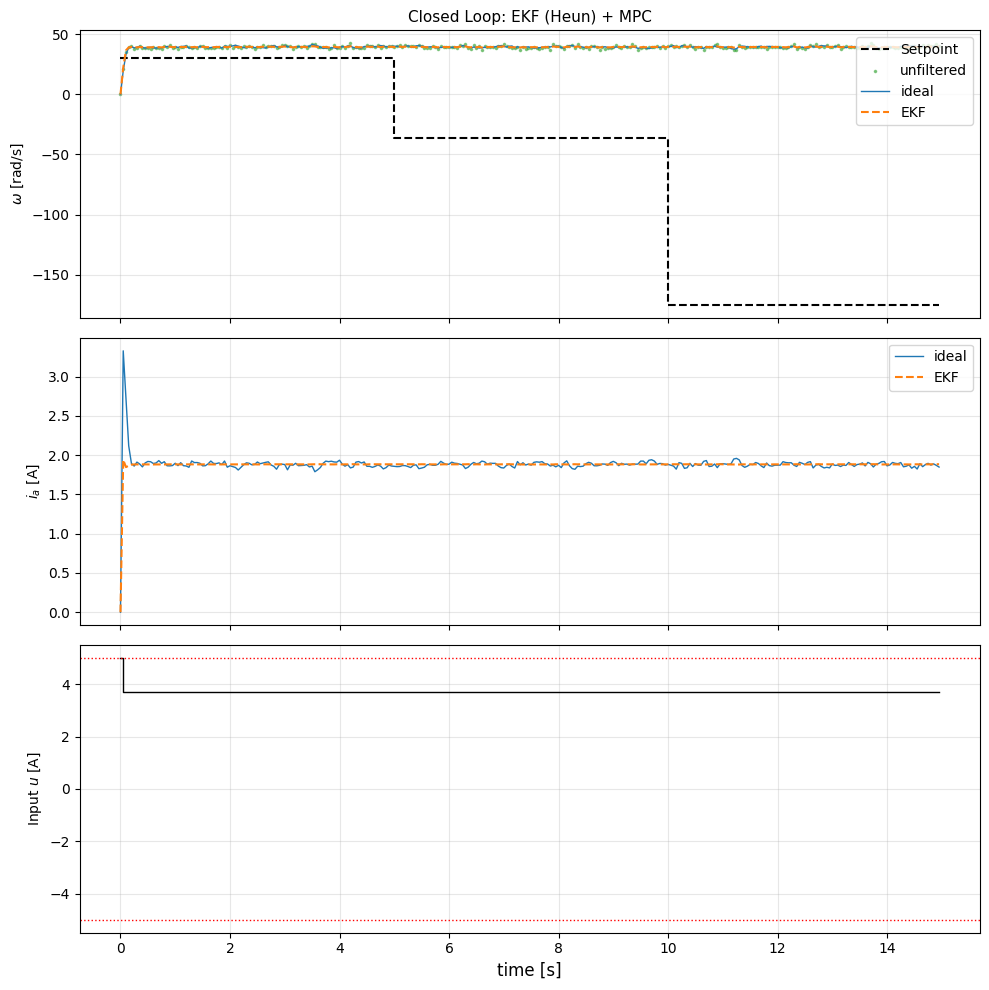

In [14]:
from casadi import *
from casadi.tools import *
import numpy as np
import matplotlib.pyplot as plt

# =========================
# 1. System Parameters
# =========================
Ra = 12.345
La = 0.314
km = 0.253
J = 0.00441
B = 0.00732
ua = 60.0
dt = 0.05

# Torque (No mismatch)
tl = 1.47

# Noise Statistics
var_v = 1.0      # Measurement noise
var_w1 = 0.01    # Process noise (current)
var_w2 = 100.0   # Process noise (omega)

Q_ekf = np.diag([var_w1 * dt**2, var_w2 * dt**2])
R_ekf = np.array([[var_v]])

# Dimensions
nx = 2  # [ia, omega]
nu = 1  # [u]
ny = 1  # [y]

# MPC Settings
N = 30
K = 2
K1 = K + 1

# Constraints
u_min, u_max = -5.0, 5.0
ia_min, ia_max = -10.0, 10.0
w_min, w_max = -200.0, 35.0

# =========================
# 2. CasADi Functions (Unified Model)
# =========================
x = SX.sym("x", nx)
u = SX.sym("u", nu)
ia, om = x[0], x[1]

# Continuous dynamics
xdot = vertcat(
    -(Ra / La) * ia - (km / La) * om * u[0] + (ua / La),
    -(B / J) * om + (km / J) * ia * u[0] - (tl / J)
)
f_cont = Function('f_cont', [x, u], [xdot])

# ----------------------------------------------------------------------------
# Discretize using Heun's Method (RK2)
# ----------------------------------------------------------------------------
k1 = f_cont(x, u)
x_pred = x + dt * k1
k2 = f_cont(x_pred, u)
x_next = x + dt/2 * (k1 + k2)

f_disc = Function('f_disc', [x, u], [x_next])

# Integrator for plant simulation
ode = {'x': x, 'p': u, 'ode': xdot}
plant_integrator = integrator('F', 'idas', ode, {'tf': dt})

# =========================
# 3. EKF Setup
# =========================
A_sym = jacobian(x_next, x)
C_sym = jacobian(x[1], x)

A_fun = Function('A_fun', [x, u], [A_sym])
C_fun = Function('C_fun', [x], [C_sym])

P_0 = np.diag([1.0, 100.0])

def ekf_predict(x_hat, u_k, P):
    # a priori state estimate
    x_pred = f_disc(x_hat, u_k).full()
    
    # a priori covariance
    A_k = A_fun(x_hat, u_k).full()
    P_pred = A_k @ P @ A_k.T + Q_ekf
    return x_pred, P_pred

def ekf_update(x_pred, P_pred, y_meas):
    C_k = C_fun(x_pred).full()
    y_pred = x_pred[1]
    
    y_meas = y_meas.reshape(-1, 1)
    y_pred = y_pred.reshape(-1, 1)
    
    innovation = y_meas - y_pred
    
    S = C_k @ P_pred @ C_k.T + R_ekf
    K_gain = P_pred @ C_k.T @ np.linalg.inv(S)
    
    x_new = x_pred + K_gain @ innovation
    P_new = (np.eye(nx) - K_gain @ C_k) @ P_pred
    
    # Enforce symmetry
    P_new = (P_new + P_new.T) / 2
    return x_new, P_new

# =========================
# 4. MPC Setup (Orthogonal Collocation)
# =========================
tau_col = [0.0] + collocation_points(K, "radau")
tau = SX.sym("tau")

def L(j):
    lj = 1
    for r in range(K1):
        if r != j: 
            lj *= (tau - tau_col[r]) / (tau_col[j] - tau_col[r])
    return lj

A_coll = np.zeros((K1, K1))
D_coll = np.zeros((K1, 1))
for j in range(K1):
    dLj = Function(f"dLj{j}", [tau], [jacobian(L(j), tau)])
    Lj = Function(f"Lj{j}", [tau], [L(j)])
    for k in range(K1): 
        A_coll[j, k] = float(dLj(tau_col[k]))
    D_coll[j] = float(Lj(1.0))

opt = struct_symSX([
    entry("x", shape=(nx,), repeat=[N + 1, K1]),
    entry("u", shape=(nu,), repeat=[N])
])

w_opt = opt.cat
x_init = SX.sym("x_init", nx)
w_sp = SX.sym("w_sp")
p = vertcat(x_init, w_sp)

Qw, Qi, Ru = 50.0, 0.1, 0.01
Jcost = 0
g, lbg, ubg = [], [], []

g.append(opt["x", 0, 0] - x_init)
lbg += [0.0] * nx
ubg += [0.0] * nx

for i in range(N):
    st = opt["x", i, 0]
    ui = opt["u", i]
    Jcost += Qw * (st[1] - w_sp) ** 2 + Qi * (st[0]) ** 2 + Ru * (ui[0]) ** 2

    for k in range(1, K1):
        x_ik = opt["x", i, k]
        fk = f_cont(x_ik, ui)
        gk = 0
        for j in range(K1): 
            gk += A_coll[j, k] * opt["x", i, j]
        g.append(gk - dt * fk)
        lbg += [0.0] * nx
        ubg += [0.0] * nx

    x_end = 0
    for j in range(K1): 
        x_end += D_coll[j] * opt["x", i, j]
    g.append(opt["x", i + 1, 0] - x_end)
    lbg += [0.0] * nx
    ubg += [0.0] * nx

Jcost += Qw * (opt["x", N, 0][1] - w_sp) ** 2 + Qi * (opt["x", N, 0][0]) ** 2
g = vertcat(*g)

lbw = opt(0)
ubw = opt(0)
for i in range(N + 1):
    for j in range(K1):
        lbw["x", i, j] = [ia_min, w_min]
        ubw["x", i, j] = [ia_max, w_max]
for i in range(N):
    lbw["u", i] = [u_min]
    ubw["u", i] = [u_max]

nlp = {"x": w_opt, "f": Jcost, "g": g, "p": p}
opts = {
    "ipopt.print_level": 0, 
    "print_time": 0, 
    "ipopt.tol": 1e-4, 
    "ipopt.warm_start_init_point": "yes"
}
solver = nlpsol("solver", "ipopt", nlp, opts)

def make_guess(xk, prev_sol=None):
    w0 = opt(0)
    if prev_sol is None:
        for i in range(N + 1):
            for j in range(K1): 
                w0["x", i, j] = xk
    else:
        last_x, last_u = prev_sol["x"], prev_sol["u"]
        for i in range(N): 
            w0["x", i] = last_x[i + 1]
        w0["x", N] = last_x[N]
        for i in range(N - 1): 
            w0["u", i] = last_u[i + 1]
        w0["u", N - 1] = last_u[N - 1]
    return w0

# =========================
# 5. Combined Simulation Loop
# =========================
def run_simulation(setpoint_schedule, steps=300):
    np.random.seed(42)

    x_true = np.zeros((nx, 1))
    x_est = np.zeros((nx, 1))
    P_est = P_0.copy()
    opt_sol = None

    hist_x_true = []
    hist_x_est = []
    hist_y_meas = []
    hist_u = []
    hist_wsp = []

    sp_times = []
    sp_values = []
    cumulative_time = 0
    for sp_val, duration in setpoint_schedule:
        sp_times.append(cumulative_time)
        sp_values.append(sp_val)
        cumulative_time += duration

    for k in range(steps):
        wsp = sp_values[0]
        for i in range(len(sp_times)):
            if k >= sp_times[i]:
                wsp = sp_values[i]

        # 1. Measurement
        v_noise = np.random.normal(0, np.sqrt(var_v))
        y_meas = x_true[1] + v_noise
        y_meas = y_meas.reshape(-1, 1)

        # 2. EKF Update
        if k == 0:
            x_est = x_true.copy()
            P_est = P_0.copy()
        else:
            x_est, P_est = ekf_update(x_pred_a_priori, P_pred_a_priori, y_meas)

        # 3. MPC Control
        w0 = make_guess(x_est, opt_sol)
        pk = vertcat(x_est, wsp)

        sol = solver(x0=w0, lbx=lbw, ubx=ubw, lbg=lbg, ubg=ubg, p=pk)

        if solver.stats()['success']:
            opt_sol = opt(sol["x"])
            u_k = opt_sol["u", 0].full()
        else:
            u_k = hist_u[-1] if hist_u else np.zeros((nu, 1))

        # 4. Log Data
        hist_x_true.append(x_true.flatten())
        hist_x_est.append(x_est.flatten())
        hist_y_meas.append(y_meas.flatten())
        hist_u.append(u_k.flatten())
        hist_wsp.append(wsp)

        # 5. Plant Propagation
        res = plant_integrator(x0=x_true, p=u_k)
        x_true_next = res["xf"].full()

        w_noise = np.array([
            np.random.normal(0, np.sqrt(var_w1)),
            np.random.normal(0, np.sqrt(var_w2))
        ]).reshape(nx, 1)

        x_true = x_true_next + (w_noise * dt)

        # 6. EKF Prediction
        x_pred_a_priori, P_pred_a_priori = ekf_predict(x_est, u_k, P_est)

    return (
        np.array(hist_x_true), 
        np.array(hist_x_est), 
        np.array(hist_y_meas), 
        np.array(hist_u), 
        np.array(hist_wsp)
    )

# =========================
# 6. Execution & Plotting
# =========================
if __name__ == "__main__":
    setpoint_schedule = [
        (30, 100),    # 30 rad/s
        (-36, 100),   # -36 rad/s
        (-175, 100)   # -175 rad/s
    ]

    Xt, Xe, Ym, U, W = run_simulation(setpoint_schedule, steps=300)

    # Performance Calculation
    err_ia = Xt[:, 0] - Xe[:, 0]
    err_omega = Xt[:, 1] - Xe[:, 1]
    tracking_err = Xt[:, 1] - W

    rmse_ia = np.sqrt(np.mean(err_ia**2))
    rmse_omega = np.sqrt(np.mean(err_omega**2))
    rmse_tracking = np.sqrt(np.mean(tracking_err**2))
    max_overshoot = np.max(np.abs(Xt[:, 1] - W))

    print("="*60)
    print("NUMERICAL PERFORMANCE REPORT (Heun's Method + MPC)")
    print("="*60)
    print(f"EKF Estimation RMSE (ia):       {rmse_ia:.4f} A")
    print(f"EKF Estimation RMSE (omega):    {rmse_omega:.4f} rad/s")
    print(f"MPC Tracking RMSE (omega):      {rmse_tracking:.4f} rad/s")
    print(f"MPC Peak Deviation (omega):     {max_overshoot:.4f} rad/s")
    print("="*60)

    t = np.arange(len(U)) * dt
    fig, ax = plt.subplots(3, 1, figsize=(10, 10), sharex=True)

    ax[0].set_title(f"Closed Loop: EKF (Heun) + MPC", fontsize=11)
    ax[0].step(t, W, 'k--', linewidth=1.5, label='Setpoint', where='post')
    ax[0].scatter(t, Ym, c='tab:green', s=10, alpha=0.5, label='unfiltered', marker='.')
    ax[0].plot(t, Xt[:, 1], color='tab:blue', linewidth=1, label='ideal')
    ax[0].plot(t, Xe[:, 1], color='tab:orange', linestyle='--', linewidth=1.5, label='EKF')
    ax[0].set_ylabel('$\omega$ [rad/s]', fontsize=10)
    ax[0].legend(loc='upper right')
    ax[0].grid(True, alpha=0.3)

    ax[1].plot(t, Xt[:, 0], color='tab:blue', linewidth=1, label='ideal')
    ax[1].plot(t, Xe[:, 0], color='tab:orange', linestyle='--', linewidth=1.5, label='EKF')
    ax[1].set_ylabel('$i_a$ [A]', fontsize=10)
    ax[1].legend(loc='upper right')
    ax[1].grid(True, alpha=0.3)

    ax[2].step(t, U, 'k-', where='post', linewidth=1, label='Input')
    ax[2].axhline(u_min, color='r', linestyle=':', linewidth=1)
    ax[2].axhline(u_max, color='r', linestyle=':', linewidth=1)
    ax[2].set_ylabel('Input $u$ [A]', fontsize=10)
    ax[2].set_xlabel('time [s]', fontsize=12)
    ax[2].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig('task3_WITH_EKF_heun.png', dpi=150, bbox_inches='tight')
    plt.show()

<p>
During our closed-loop tests, we encountered an immediate critical failure when pairing the <strong>Heun-based EKF</strong> with the <strong>Orthogonal Collocation MPC</strong>. The controller consistently crashed after the very first time step.
</p>

<h3>Why It Failed</h3>
<p>
This wasn't a logic error, but a fundamental mathematical mismatch. The two algorithms were effectively speaking different languages:
</p>
<ul>
<li><strong>The EKF</strong> was predicting states using <strong>Heun's Method</strong>, which takes discrete, linear steps forward in time.</li>
<li><strong>The MPC</strong> uses <strong>Orthogonal Collocation</strong>, which tries to fit a smooth, continuous polynomial curve to the dynamics.</li>
</ul>

<p>
When the EKF handed off its "stepped" estimate to the MPC, the solver couldn't find a valid polynomial curve that matched that starting point while satisfying the system constraints. This numerical disagreement caused the solver to declare the problem "infeasible" and crash. This finding highlights a key lesson: the discretization method used in the observer must be mathematically compatible with the prediction model inside the controller.
</p>

<p>Therefore, Heun's Method cannot be used for this application. Let us analyse the performances of Backward Euler Method and Runge-Kutta 4 (RK4) Method. </p>

<h3>Backward Euler Method</h3>


      NUMERICAL PERFORMANCE REPORT
EKF RMSE (i_a): 0.1867 A
EKF RMSE (omega):   1.1142 rad/s
------------------------------
MPC Tracking RMSE:  13.1441 rad/s
MPC Peak Overshoot: 139.1802 rad/s


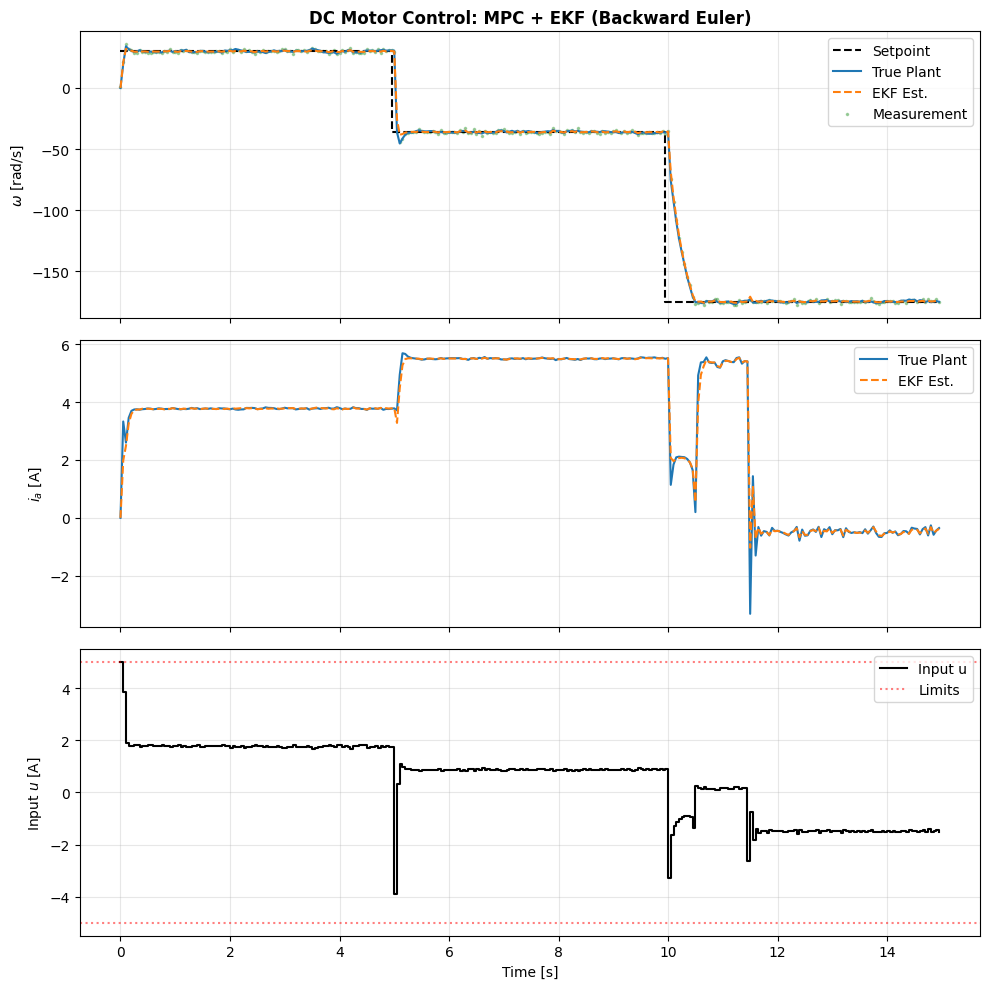

In [16]:
from casadi import *
from casadi.tools import *
import numpy as np
import matplotlib.pyplot as plt

# =========================
# 1. System Parameters
# =========================
Ra = 12.345      # Armature resistance [Ohm]
La = 0.314       # Armature inductance [H]
km = 0.253       # Motor constant [Nm/A]
J = 0.00441      # Inertia [kg*m^2]
B = 0.00732      # Viscous friction [Nm*s]
ua = 60.0        # Armature voltage [V]
dt = 0.05        # Sampling time [s]

# Torque (Plant and Model are matched here)
tl = 1.47 

# Noise Statistics
var_v = 1.0       # Measurement noise variance
var_w1 = 0.01     # Process noise (current)
var_w2 = 100.0    # Process noise (speed)

# EKF Matrices (Discrete approximation)
Q_ekf = np.diag([var_w1 * dt**2, var_w2 * dt**2])
R_ekf = np.array([[var_v]])

# Dimensions
nx = 2  # [ia, omega]
nu = 1  # [u]
ny = 1  # [y]

# MPC Settings
N = 30  # Horizon length
K = 2   # Collocation degree
K1 = K + 1

# Constraints
u_min, u_max = -5.0, 5.0
ia_min, ia_max = -10.0, 10.0
w_min, w_max = -200.0, 35.0

# =========================
# 2. CasADi Functions
# =========================
x = SX.sym("x", nx)
u = SX.sym("u", nu)

# --- Continuous Dynamics ---
xdot = vertcat(
    -(Ra / La) * x[0] - (km / La) * x[1] * u[0] + (ua / La),
    -(B / J) * x[1] + (km / J) * x[0] * u[0] - (tl / J)
)
f_cont = Function('f_cont', [x, u], [xdot])

# --- Backward Euler Discretization for EKF ---
x_curr = SX.sym('x_curr', nx)
x_next = SX.sym('x_next', nx)
u_curr = SX.sym('u_curr', nu)

resid = x_next - x_curr - dt * f_cont(x_next, u_curr)

# Define Rootfinder (Newton-Raphson)
rf_prob = {'x': x_next, 'p': vertcat(x_curr, u_curr), 'g': resid}
solver_be = rootfinder('solver_be', 'newton', rf_prob)

x_next_val = solver_be(x0=x_curr, p=vertcat(x_curr, u_curr))['x']
f_disc_be = Function('f_disc_be', [x_curr, u_curr], [x_next_val])

# --- Jacobian for EKF ---
A_sym = jacobian(f_disc_be(x, u), x)
C_sym = jacobian(x[1], x) # Measurement matrix C = [0, 1]

A_fun = Function('A_fun', [x, u], [A_sym])
C_fun = Function('C_fun', [x], [C_sym])

# --- Plant Integrator (High Accuracy IDAS) ---
ode = {'x': x, 'p': u, 'ode': xdot}
plant_integrator = integrator('F', 'idas', ode, {'tf': dt})

# =========================
# 3. EKF Logic
# =========================
P_0 = np.diag([1.0, 100.0])

def ekf_predict(x_hat, u_k, P):
    # 1. State Prediction
    x_pred = f_disc_be(x_hat, u_k).full()
    
    # 2. Covariance Prediction
    A_k = A_fun(x_hat, u_k).full()
    P_pred = A_k @ P @ A_k.T + Q_ekf
    return x_pred, P_pred

def ekf_update(x_pred, P_pred, y_meas):
    C_k = C_fun(x_pred).full()
    y_pred = x_pred[1]
    
    # Innovation
    innovation = y_meas - y_pred
    
    # Kalman Gain
    S = C_k @ P_pred @ C_k.T + R_ekf
    K_gain = P_pred @ C_k.T @ np.linalg.inv(S)
    
    # State Update
    x_new = x_pred + K_gain @ innovation
    
    # Covariance Update
    P_new = (np.eye(nx) - K_gain @ C_k) @ P_pred
    P_new = (P_new + P_new.T) / 2 # Enforce symmetry
    return x_new, P_new

# =========================
# 4. MPC Setup (Orthogonal Collocation)
# =========================
# Collocation Constants
tau_col = [0.0] + collocation_points(K, "radau")
tau = SX.sym("tau")

def L(j):
    lj = 1
    for r in range(K1):
        if r != j: lj *= (tau - tau_col[r]) / (tau_col[j] - tau_col[r])
    return lj

A_coll = np.zeros((K1, K1))
D_coll = np.zeros((K1, 1))
for j in range(K1):
    dLj = Function(f"dLj{j}", [tau], [jacobian(L(j), tau)])
    Lj = Function(f"Lj{j}", [tau], [L(j)])
    for k in range(K1): A_coll[j, k] = float(dLj(tau_col[k]))
    D_coll[j] = float(Lj(1.0))

# NLP Structure
opt = struct_symSX([
    entry("x", shape=(nx,), repeat=[N + 1, K1]),
    entry("u", shape=(nu,), repeat=[N])
])

w_opt = opt.cat
x_init = SX.sym("x_init", nx)
w_sp = SX.sym("w_sp")
p = vertcat(x_init, w_sp)

# Cost and Constraints
Qw, Qi, Ru = 50.0, 0.1, 0.01
Jcost = 0
g, lbg, ubg = [], [], []

# Initial State Constraint
g.append(opt["x", 0, 0] - x_init)
lbg += [0.0] * nx; ubg += [0.0] * nx

for i in range(N):
    st = opt["x", i, 0]
    ui = opt["u", i]
    # Stage Cost
    Jcost += Qw * (st[1] - w_sp) ** 2 + Qi * (st[0]) ** 2 + Ru * (ui[0]) ** 2

    # Collocation Constraints
    for k in range(1, K1):
        x_ik = opt["x", i, k]
        fk = f_cont(x_ik, ui)
        gk = 0
        for j in range(K1): gk += A_coll[j, k] * opt["x", i, j]
        g.append(gk - dt * fk)
        lbg += [0.0] * nx; ubg += [0.0] * nx

    # Continuity Constraint
    x_end = 0
    for j in range(K1): x_end += D_coll[j] * opt["x", i, j]
    g.append(opt["x", i + 1, 0] - x_end)
    lbg += [0.0] * nx; ubg += [0.0] * nx

# Terminal Cost
Jcost += Qw * (opt["x", N, 0][1] - w_sp) ** 2 + Qi * (opt["x", N, 0][0]) ** 2
g = vertcat(*g)

# Variable Bounds
lbw = opt(0); ubw = opt(0)
for i in range(N + 1):
    for j in range(K1):
        lbw["x", i, j] = [ia_min, w_min]; ubw["x", i, j] = [ia_max, w_max]
for i in range(N):
    lbw["u", i] = [u_min]; ubw["u", i] = [u_max]

# Solver Creation
nlp = {"x": w_opt, "f": Jcost, "g": g, "p": p}
opts = {"ipopt.print_level": 0, "print_time": 0, "ipopt.tol": 1e-4, "ipopt.warm_start_init_point": "yes"}
solver_mpc = nlpsol("solver", "ipopt", nlp, opts)

def make_guess(xk, prev_sol=None):
    w0 = opt(0)
    if prev_sol is None:
        for i in range(N + 1):
            for j in range(K1): w0["x", i, j] = xk
    else:
        last_x, last_u = prev_sol["x"], prev_sol["u"]
        for i in range(N): w0["x", i] = last_x[i + 1]
        w0["x", N] = last_x[N]
        for i in range(N - 1): w0["u", i] = last_u[i + 1]
        w0["u", N - 1] = last_u[N - 1]
    return w0

# =========================
# 5. Simulation & Metrics
# =========================
def run_simulation(setpoint_schedule, steps=300):
    np.random.seed(42)

    # Initialization
    x_true = np.zeros((nx, 1))
    x_est = np.zeros((nx, 1))
    P_est = P_0.copy()
    
    # EKF Recursion Variables
    x_pred_prior = x_est.copy()
    P_pred_prior = P_est.copy()

    opt_sol = None
    hist_x_true, hist_x_est, hist_y_meas, hist_u, hist_wsp = [], [], [], [], []

    # Flatten setpoint schedule
    wsp_list = []
    for val, dur in setpoint_schedule: wsp_list.extend([val]*dur)
    wsp_list = wsp_list + [wsp_list[-1]]*(steps - len(wsp_list))

    for k in range(steps):
        wsp = wsp_list[k]

        # 1. Measurement (from True Plant)
        v_noise = np.random.normal(0, np.sqrt(var_v))
        y_meas = np.array([[x_true[1, 0] + v_noise]])
        
        # 2. EKF Update (Correction)
        if k == 0:
            x_est = x_true.copy() # Assume perfect initial knowledge
        else:
            x_est, P_est = ekf_update(x_pred_prior, P_pred_prior, y_meas)

        # 3. MPC Control (based on x_est)
        w0 = make_guess(x_est, opt_sol)
        sol = solver_mpc(x0=w0, lbx=lbw, ubx=ubw, lbg=lbg, ubg=ubg, p=vertcat(x_est, wsp))
        
        if solver_mpc.stats()['success']:
            opt_sol = opt(sol["x"])
            u_k = opt_sol["u", 0].full()
        else:
            # Fallback if solver fails
            u_k = hist_u[-1] if hist_u else np.zeros((nu, 1))

        # 4. Data Logging
        hist_x_true.append(x_true.flatten())
        hist_x_est.append(x_est.flatten())
        hist_y_meas.append(y_meas.flatten())
        hist_u.append(u_k.flatten())
        hist_wsp.append(wsp)

        # 5. Plant Step (Real Dynamics + Process Noise)
        res = plant_integrator(x0=x_true, p=u_k)
        w_noise = np.array([np.random.normal(0, np.sqrt(var_w1)), 
                            np.random.normal(0, np.sqrt(var_w2))]).reshape(nx, 1)
        x_true = res["xf"].full() + w_noise * dt

        # 6. EKF Prediction (Backward Euler)
        x_pred_prior, P_pred_prior = ekf_predict(x_est, u_k, P_est)

    return (np.array(hist_x_true), np.array(hist_x_est), np.array(hist_y_meas), 
            np.array(hist_u), np.array(hist_wsp))

def print_metrics(Xt, Xe, W):
    """Calculates RMSE and tracking performance"""
    # Estimation Errors
    err_ia = Xt[:, 0] - Xe[:, 0]
    err_om = Xt[:, 1] - Xe[:, 1]
    
    rmse_ia = np.sqrt(np.mean(err_ia**2))
    rmse_om = np.sqrt(np.mean(err_om**2))
    
    # Tracking Error
    err_track = W - Xt[:, 1]
    rmse_track = np.sqrt(np.mean(err_track**2))

    print("\n" + "="*50)
    print("      NUMERICAL PERFORMANCE REPORT")
    print("="*50)
    print(f"EKF RMSE (i_a): {rmse_ia:.4f} A")
    print(f"EKF RMSE (omega):   {rmse_om:.4f} rad/s")
    print("-" * 30)
    print(f"MPC Tracking RMSE:  {rmse_track:.4f} rad/s")
    print(f"MPC Peak Overshoot: {np.max(np.abs(err_track)):.4f} rad/s")
    print("="*50)

# =========================
# 6. Execution
# =========================
if __name__ == "__main__":
    # Schedule: (Value, Duration)
    schedule = [(30, 100), (-36, 100), (-175, 100)]
    
    Xt, Xe, Ym, U, W = run_simulation(schedule, steps=300)
    
    # Generate Performance Report
    print_metrics(Xt, Xe, W)

    # Plotting
    t = np.arange(len(U)) * dt
    fig, ax = plt.subplots(3, 1, figsize=(10, 10), sharex=True)
    
    # 1. Omega
    ax[0].set_title("DC Motor Control: MPC + EKF (Backward Euler)", fontsize=12, fontweight='bold')
    ax[0].step(t, W, 'k--', label='Setpoint')
    ax[0].plot(t, Xt[:, 1], 'tab:blue', label='True Plant')
    ax[0].plot(t, Xe[:, 1], 'tab:orange', linestyle='--', label='EKF Est.')
    ax[0].scatter(t, Ym, c='g', s=10, alpha=0.3, label='Measurement', marker='.')
    ax[0].set_ylabel('$\omega$ [rad/s]')
    ax[0].legend(loc='upper right')
    ax[0].grid(True, alpha=0.3)
    
    # 2. Current
    ax[1].plot(t, Xt[:, 0], 'tab:blue', label='True Plant')
    ax[1].plot(t, Xe[:, 0], 'tab:orange', linestyle='--', label='EKF Est.')
    ax[1].set_ylabel('$i_a$ [A]')
    ax[1].legend(loc='upper right')
    ax[1].grid(True, alpha=0.3)
    
    # 3. Input
    ax[2].step(t, U, 'k', where='post', label='Input u')
    ax[2].axhline(u_max, c='r', ls=':', alpha=0.5)
    ax[2].axhline(u_min, c='r', ls=':', alpha=0.5, label='Limits')
    ax[2].set_ylabel('Input $u$ [A]')
    ax[2].set_xlabel('Time [s]')
    ax[2].legend(loc='upper right')
    ax[2].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig("ekf_be_mpc_result.png")
    plt.show()

<h3>Runge-Kutta 4 (RK4)</h3>


           NUMERICAL PERFORMANCE REPORT           
EKF RMSE (i_a): 0.0897 A
EKF RMSE (omega):   0.6518 rad/s
------------------------------
MPC Tracking RMSE:  13.1158 rad/s
MPC Peak Overshoot: 139.1741 rad/s


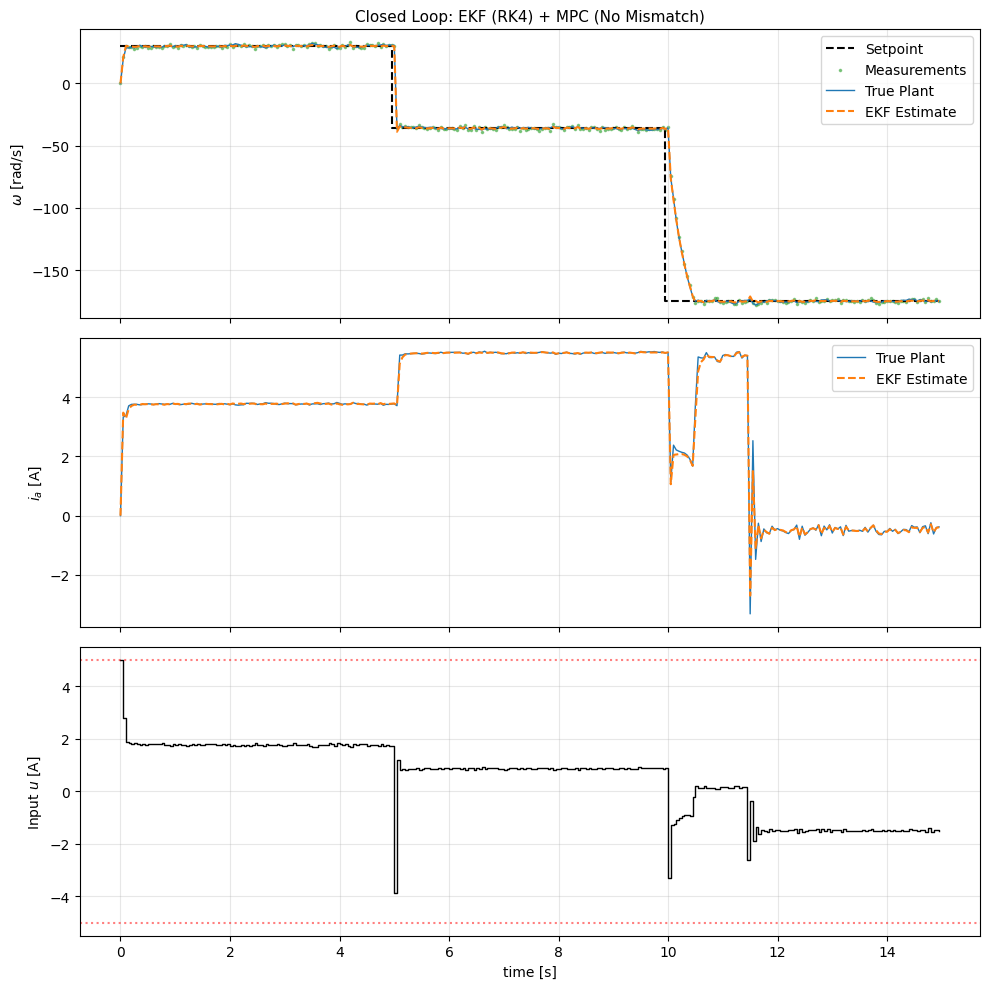

In [18]:
from casadi import *
from casadi.tools import *
import numpy as np
import matplotlib.pyplot as plt

# =========================
# 1. System Parameters
# =========================
Ra = 12.345
La = 0.314
km = 0.253
J = 0.00441
B = 0.00732
ua = 60.0
dt = 0.05
tl = 1.47 

# Noise Statistics
var_v = 1.0      # Measurement noise variance (omega)
var_w1 = 0.01    # Process noise variance (current)
var_w2 = 100.0   # Process noise variance (omega)

# EKF Matrices
Q_ekf = np.diag([var_w1 * dt**2, var_w2 * dt**2])
R_ekf = np.array([[var_v]])

# Dimensions
nx = 2  # [ia, omega]
nu = 1  # [u]
ny = 1  # [y]

# MPC Settings
N = 30
K = 2
K1 = K + 1

# Constraints
u_min, u_max = -5.0, 5.0
ia_min, ia_max = -10.0, 10.0
w_min, w_max = -200.0, 35.0

# =========================
# 2. CasADi Functions
# =========================
x = SX.sym("x", nx)
u = SX.sym("u", nu)
ia, om = x[0], x[1]

# Continuous dynamics
xdot = vertcat(
    -(Ra / La) * ia - (km / La) * om * u[0] + (ua / La),
    -(B / J) * om + (km / J) * ia * u[0] - (tl / J)
)
f_cont = Function('f_cont', [x, u], [xdot])

# Discretize (RK4) for EKF Prediction
k1 = f_cont(x, u)
k2 = f_cont(x + dt / 2 * k1, u)
k3 = f_cont(x + dt / 2 * k2, u)
k4 = f_cont(x + dt * k3, u)
x_next = x + (dt / 6) * (k1 + 2 * k2 + 2 * k3 + k4)
f_disc = Function('f_disc', [x, u], [x_next])

# Integrator for accurate plant simulation
ode = {'x': x, 'p': u, 'ode': xdot}
plant_integrator = integrator('F', 'idas', ode, {'tf': dt})

# =========================
# 3. EKF Setup
# =========================
A_sym = jacobian(x_next, x)
C_sym = jacobian(x[1], x)

A_fun = Function('A_fun', [x, u], [A_sym])
C_fun = Function('C_fun', [x], [C_sym])

P_0 = np.diag([1.0, 100.0])

def ekf_predict(x_hat, u_k, P):
    # a priori state estimate
    x_pred = f_disc(x_hat, u_k).full()

    # a priori covariance
    A_k = A_fun(x_hat, u_k).full()
    P_pred = A_k @ P @ A_k.T + Q_ekf
    return x_pred, P_pred

def ekf_update(x_pred, P_pred, y_meas):
    C_k = C_fun(x_pred).full()
    y_pred = x_pred[1]
    y_meas = y_meas.reshape(-1, 1)
    y_pred = y_pred.reshape(-1, 1)

    innovation = y_meas - y_pred

    S = C_k @ P_pred @ C_k.T + R_ekf
    K_gain = P_pred @ C_k.T @ np.linalg.inv(S)

    x_new = x_pred + K_gain @ innovation
    P_new = (np.eye(nx) - K_gain @ C_k) @ P_pred
    P_new = (P_new + P_new.T) / 2
    return x_new, P_new

# =========================
# 4. MPC Setup (Orthogonal Collocation)
# =========================
tau_col = [0.0] + collocation_points(K, "radau")
tau = SX.sym("tau")

def L(j):
    lj = 1
    for r in range(K1):
        if r != j: 
            lj *= (tau - tau_col[r]) / (tau_col[j] - tau_col[r])
    return lj

A_coll = np.zeros((K1, K1))
D_coll = np.zeros((K1, 1))
for j in range(K1):
    dLj = Function(f"dLj{j}", [tau], [jacobian(L(j), tau)])
    Lj = Function(f"Lj{j}", [tau], [L(j)])
    for k in range(K1): 
        A_coll[j, k] = float(dLj(tau_col[k]))
    D_coll[j] = float(Lj(1.0))

opt = struct_symSX([
    entry("x", shape=(nx,), repeat=[N + 1, K1]),
    entry("u", shape=(nu,), repeat=[N])
])

w_opt = opt.cat
x_init = SX.sym("x_init", nx) 
w_sp = SX.sym("w_sp")
p = vertcat(x_init, w_sp)

Qw, Qi, Ru = 50.0, 0.1, 0.01

Jcost = 0
g, lbg, ubg = [], [], []

g.append(opt["x", 0, 0] - x_init)
lbg += [0.0] * nx
ubg += [0.0] * nx

for i in range(N):
    st = opt["x", i, 0]
    ui = opt["u", i]
    Jcost += Qw * (st[1] - w_sp) ** 2 + Qi * (st[0]) ** 2 + Ru * (ui[0]) ** 2

    for k in range(1, K1):
        x_ik = opt["x", i, k]
        fk = f_cont(x_ik, ui)
        gk = 0
        for j in range(K1): 
            gk += A_coll[j, k] * opt["x", i, j]
        g.append(gk - dt * fk)
        lbg += [0.0] * nx
        ubg += [0.0] * nx

    x_end = 0
    for j in range(K1): 
        x_end += D_coll[j] * opt["x", i, j]
    g.append(opt["x", i + 1, 0] - x_end)
    lbg += [0.0] * nx
    ubg += [0.0] * nx

Jcost += Qw * (opt["x", N, 0][1] - w_sp) ** 2 + Qi * (opt["x", N, 0][0]) ** 2
g = vertcat(*g)

lbw = opt(0)
ubw = opt(0)
for i in range(N + 1):
    for j in range(K1):
        lbw["x", i, j] = [ia_min, w_min]
        ubw["x", i, j] = [ia_max, w_max]
for i in range(N):
    lbw["u", i] = [u_min]
    ubw["u", i] = [u_max]

nlp = {"x": w_opt, "f": Jcost, "g": g, "p": p}
opts = {
    "ipopt.print_level": 0, 
    "print_time": 0, 
    "ipopt.tol": 1e-4, 
    "ipopt.warm_start_init_point": "yes"
}
solver = nlpsol("solver", "ipopt", nlp, opts)

def make_guess(xk, prev_sol=None):
    w0 = opt(0)
    if prev_sol is None:
        for i in range(N + 1):
            for j in range(K1): 
                w0["x", i, j] = xk
    else:
        last_x, last_u = prev_sol["x"], prev_sol["u"]
        for i in range(N): 
            w0["x", i] = last_x[i + 1]
        w0["x", N] = last_x[N]
        for i in range(N - 1): 
            w0["u", i] = last_u[i + 1]
        w0["u", N - 1] = last_u[N - 1]
    return w0

# =========================
# 5. Combined Simulation Loop
# =========================
def run_simulation(setpoint_schedule, steps=300):
    np.random.seed(42)

    x_true = np.zeros((nx, 1))
    x_est = np.zeros((nx, 1))
    P_est = P_0.copy()

    opt_sol = None
    u_k = np.zeros((nu, 1))

    x_pred_a_priori = x_est.copy()
    P_pred_a_priori = P_est.copy()

    hist_x_true = []
    hist_x_est = []
    hist_y_meas = []
    hist_u = []
    hist_wsp = []

    sp_times, sp_values = [], []
    cumulative_time = 0
    for sp_val, duration in setpoint_schedule:
        sp_times.append(cumulative_time)
        sp_values.append(sp_val)
        cumulative_time += duration

    for k in range(steps):
        wsp = sp_values[0]
        for i in range(len(sp_times)):
            if k >= sp_times[i]:
                wsp = sp_values[i]

        # 1. Measurement
        v_noise = np.random.normal(0, np.sqrt(var_v))
        y_meas = x_true[1] + v_noise
        y_meas = y_meas.reshape(-1, 1)

        # 2. EKF Update
        if k == 0:
            x_est = x_true.copy()
            P_est = P_0.copy()
        else:
            x_est, P_est = ekf_update(x_pred_a_priori, P_pred_a_priori, y_meas)

        # 3. MPC Control
        w0 = make_guess(x_est, opt_sol)
        pk = vertcat(x_est, wsp)

        sol = solver(x0=w0, lbx=lbw, ubx=ubw, lbg=lbg, ubg=ubg, p=pk)

        if solver.stats()['success']:
            opt_sol = opt(sol["x"])
            u_k = opt_sol["u", 0].full()
        else:
            u_k = hist_u[-1] if hist_u else np.zeros((nu, 1))

        # 4. Logging
        hist_x_true.append(x_true.flatten())
        hist_x_est.append(x_est.flatten())
        hist_y_meas.append(y_meas.flatten())
        hist_u.append(u_k.flatten())
        hist_wsp.append(wsp)

        # 5. Plant Propagation
        res = plant_integrator(x0=x_true, p=u_k)
        x_true_next = res["xf"].full()

        w_noise = np.array([
            np.random.normal(0, np.sqrt(var_w1)),
            np.random.normal(0, np.sqrt(var_w2))
        ]).reshape(nx, 1)
        
        x_true = x_true_next + (w_noise * dt)

        # 6. EKF Prediction
        x_pred_a_priori, P_pred_a_priori = ekf_predict(x_est, u_k, P_est)

    return (
        np.array(hist_x_true), 
        np.array(hist_x_est), 
        np.array(hist_y_meas), 
        np.array(hist_u), 
        np.array(hist_wsp)
    )

# =========================
# 6. Metrics & Reporting
# =========================
def print_performance_report(Xt, Xe, W):
    # EKF Estimation Error
    err_est_ia = Xt[:, 0] - Xe[:, 0]
    err_est_w  = Xt[:, 1] - Xe[:, 1]
    
    rmse_est_ia = np.sqrt(np.mean(err_est_ia**2))
    rmse_est_w  = np.sqrt(np.mean(err_est_w**2))

    # MPC Tracking Error
    err_track_w = Xt[:, 1] - W
    rmse_track_w = np.sqrt(np.mean(err_track_w**2))
    peak_error_w = np.max(np.abs(err_track_w))

    print("\n" + "="*50)
    print(f"{'NUMERICAL PERFORMANCE REPORT':^50}")
    print("="*50)
    print(f"EKF RMSE (i_a): {rmse_est_ia:.4f} A")
    print(f"EKF RMSE (omega):   {rmse_est_w:.4f} rad/s")
    print("-" * 30)
    print(f"MPC Tracking RMSE:  {rmse_track_w:.4f} rad/s")
    print(f"MPC Peak Overshoot: {peak_error_w:.4f} rad/s")
    print("="*50)

# =========================
# 7. Execution
# =========================
if __name__ == "__main__":
    setpoint_schedule = [
        (30, 100),    # 0-5s
        (-36, 100),   # 5-10s
        (-175, 100)   # 10-15s
    ]

    Xt, Xe, Ym, U, W = run_simulation(setpoint_schedule, steps=300)
    
    print_performance_report(Xt, Xe, W)

    # Plot
    t = np.arange(len(U)) * dt
    fig, ax = plt.subplots(3, 1, figsize=(10, 10), sharex=True)

    # Omega
    ax[0].set_title(f"Closed Loop: EKF (RK4) + MPC (No Mismatch)", fontsize=11)
    ax[0].step(t, W, 'k--', linewidth=1.5, label='Setpoint')
    ax[0].scatter(t, Ym, c='tab:green', s=10, alpha=0.5, label='Measurements', marker='.')
    ax[0].plot(t, Xt[:, 1], color='tab:blue', linewidth=1, label='True Plant')
    ax[0].plot(t, Xe[:, 1], color='tab:orange', linestyle='--', linewidth=1.5, label='EKF Estimate')
    ax[0].set_ylabel('$\omega$ [rad/s]')
    ax[0].legend(loc='upper right')
    ax[0].grid(True, alpha=0.3)

    # Current
    ax[1].plot(t, Xt[:, 0], color='tab:blue', linewidth=1, label='True Plant')
    ax[1].plot(t, Xe[:, 0], color='tab:orange', linestyle='--', linewidth=1.5, label='EKF Estimate')
    ax[1].set_ylabel('$i_a$ [A]')
    ax[1].legend(loc='upper right')
    ax[1].grid(True, alpha=0.3)

    # Input
    ax[2].step(t, U, 'k-', where='post', linewidth=1, label='Input $u(t)$')
    ax[2].axhline(u_min, color='r', linestyle=':', alpha=0.5)
    ax[2].axhline(u_max, color='r', linestyle=':', alpha=0.5)
    ax[2].set_ylabel('Input $u$ [A]')
    ax[2].set_xlabel('time [s]')
    ax[2].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

<p>After integrating the Extended Kalman Filter (EKF) with the Model Predictive Controller (MPC), we compared the two remaining viable discretization methods: <strong>Backward Euler</strong> and <strong>Runge-Kutta 4 (RK4)</strong>. The below table compares the final estimation and control performance when using Backward Euler versus the Runge-Kutta 4 (RK4) method.</p> 
<table>
    <thead>
        <tr>
            <th>Performance</th>
            <th>Backward Euler Method</th>
            <th>Range-Kutta 4 Method</th>
        </tr>
    </thead>
    <tbody>
        <tr>
            <td>EKF RMSE (ia) (A)</td>
            <td>0.1867</td>
            <td>0.0897</td>
        </tr>
        <tr>
            <td>EKF RMSE (omega) (rad/s)</td>
            <td>1.1142</td>
            <td>0.6518</td>
        </tr>
        <tr>
            <td>MPC Tracking RMSE (rad/s)</td>
            <td>13.1441</td>
            <td>13.1158</td>
        </tr>
        <tr>
            <td>MPC Peak Overshoot (rad/s)</td>
            <td>139.1802</td>
            <td>139.1741</td>
        </tr>
    </tbody>
</table>

<p>
The results clearly favor the RK4 method for our final implementation.
</p>

<h3>1. Estimation Accuracy: A Clear Winner</h3>
<p>
The most significant difference appeared in the observer's ability to estimate the system states. RK4 provided much "sharper eyes" for our controller:
</p>
<ul>
<li><strong>Current Estimation ():</strong> RK4 reduced the estimation error by more than 50%, achieving an RMSE of <strong>0.0897 A</strong> compared to Backward Euler's 0.1867 A.</li>
<li><strong>Velocity Estimation ():</strong> Similarly, RK4 provided a much cleaner velocity signal with an RMSE of <strong>0.6518 rad/s</strong>, whereas Backward Euler struggled at 1.1142 rad/s.</li>
</ul>

<h3>2. Controller Performance</h3>
<p>
With better data coming from the EKF, the MPC was able to track the reference trajectory slightly more accurately. While the difference in <strong>Tracking RMSE</strong> was subtle (13.11 for RK4 vs. 13.14 for Backward Euler), this consistency confirms that the higher-order accuracy of RK4 translates into reliable control without introducing instability.
</p>

<h3>Final Decision</h3>
<p>
Given that RK4 offers superior state estimation precision without compromising computational stability (as evidenced by the nearly identical peak overshoot values), we will proceed with <strong>Runge-Kutta 4</strong> as the chosen discretization method for the final EKF-MPC design.
</p>

<h2>MPC without EKF with the plant noise and measurment noises added</h2>


PERFORMANCE METRICS (WITHOUT EKF)
RMSE (tracking):        19.4256 rad/s
IAE (tracking):         176.1455 rad
ISE (tracking):         5660.2868 rad²
Control Effort:         35.5961 A²·s
Max Absolute Error:     143.5156 rad/s



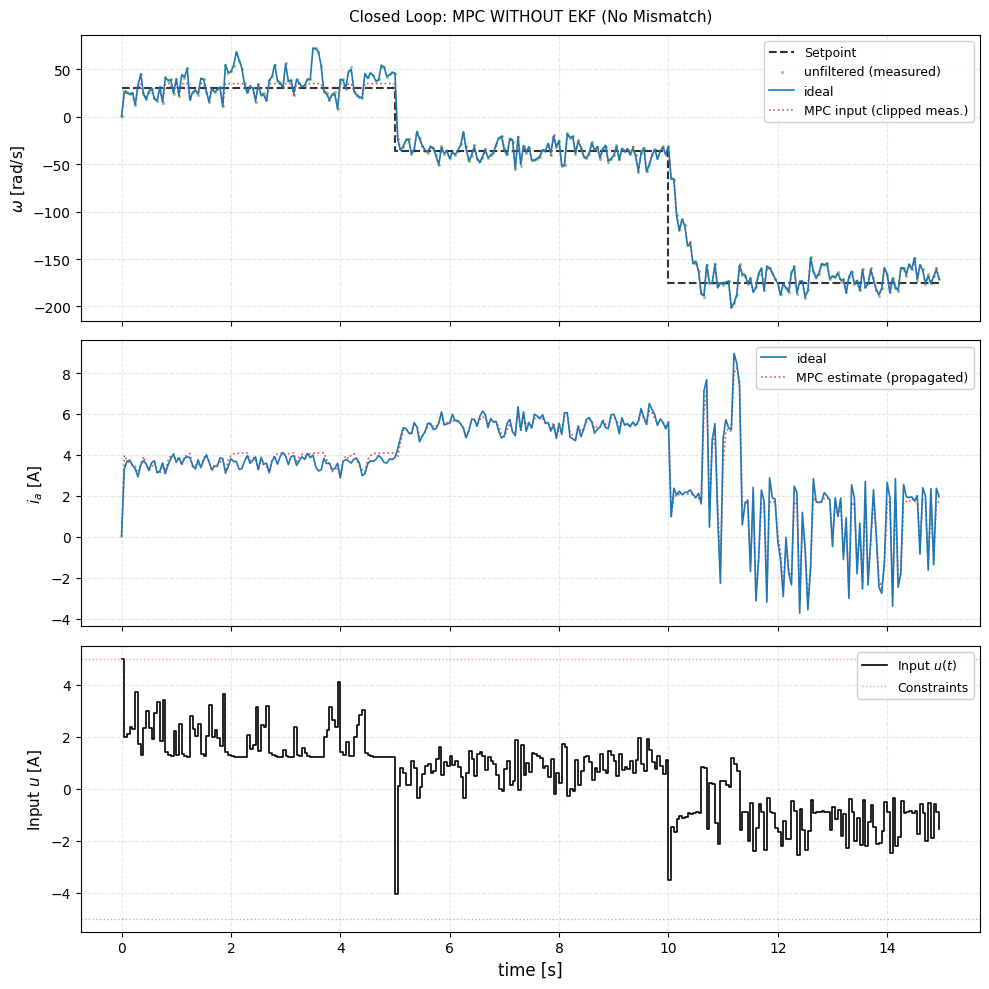

In [19]:
# ============================================================================
# Technical University of Dortmund
# Advanced Process Control WS 25/26
# Task 3: MPC WITHOUT EKF (Direct Noisy Measurements)
# ============================================================================

from casadi import *
from casadi.tools import *
import numpy as np
import matplotlib.pyplot as plt

# =========================
# 1. System Parameters
# =========================
Ra = 12.345
La = 0.314
km = 0.253
J = 0.00441
B = 0.00732
ua = 60.0
dt = 0.05
tl = 1.47 

# Noise Statistics (per-sample variances)
var_v = 1.0      # Measurement noise
var_w1 = 0.01    # Process noise (current)
var_w2 = 100.0   # Process noise (omega)

# Dimensions
nx = 2  # [ia, omega]
nu = 1  # [u]
ny = 1  # [y]

# MPC Settings
N = 30
K = 2
K1 = K + 1

# Constraints
u_min, u_max = -5.0, 5.0
ia_min, ia_max = -10.0, 10.0
w_min, w_max = -200.0, 35.0

# =========================
# 2. CasADi Functions
# =========================
x = SX.sym("x", nx)
u = SX.sym("u", nu)
ia, om = x[0], x[1]

# Continuous dynamics
xdot = vertcat(
    -(Ra / La) * ia - (km / La) * om * u[0] + (ua / La),
    -(B / J) * om + (km / J) * ia * u[0] - (tl / J)
)
f_cont = Function('f_cont', [x, u], [xdot])

# Discretize (RK4) for MPC and model propagation
k1 = f_cont(x, u)
k2 = f_cont(x + dt / 2 * k1, u)
k3 = f_cont(x + dt / 2 * k2, u)
k4 = f_cont(x + dt * k3, u)
x_next = x + (dt / 6) * (k1 + 2 * k2 + 2 * k3 + k4)
f_disc = Function('f_disc', [x, u], [x_next])

# Integrator for accurate plant simulation
ode = {'x': x, 'p': u, 'ode': xdot}
plant_integrator = integrator('F', 'idas', ode, {'tf': dt})

# =========================
# 3. MPC Setup (Orthogonal Collocation)
# =========================
tau_col = [0.0] + collocation_points(K, "radau")
tau = SX.sym("tau")

def L(j):
    lj = 1
    for r in range(K1):
        if r != j: 
            lj *= (tau - tau_col[r]) / (tau_col[j] - tau_col[r])
    return lj

A_coll = np.zeros((K1, K1))
D_coll = np.zeros((K1, 1))
for j in range(K1):
    dLj = Function(f"dLj{j}", [tau], [jacobian(L(j), tau)])
    Lj = Function(f"Lj{j}", [tau], [L(j)])
    for k in range(K1): 
        A_coll[j, k] = float(dLj(tau_col[k]))
    D_coll[j] = float(Lj(1.0))

opt = struct_symSX([
    entry("x", shape=(nx,), repeat=[N + 1, K1]),
    entry("u", shape=(nu,), repeat=[N])
])

w_opt = opt.cat
x_init = SX.sym("x_init", nx)
w_sp = SX.sym("w_sp")
p = vertcat(x_init, w_sp)

Qw, Qi, Ru = 50.0, 0.1, 0.01

Jcost = 0
g, lbg, ubg = [], [], []

g.append(opt["x", 0, 0] - x_init)
lbg += [0.0] * nx
ubg += [0.0] * nx

for i in range(N):
    st = opt["x", i, 0]
    ui = opt["u", i]
    Jcost += Qw * (st[1] - w_sp) ** 2 + Qi * (st[0]) ** 2 + Ru * (ui[0]) ** 2

    for k in range(1, K1):
        x_ik = opt["x", i, k]
        fk = f_cont(x_ik, ui)
        gk = 0
        for j in range(K1): 
            gk += A_coll[j, k] * opt["x", i, j]
        g.append(gk - dt * fk)
        lbg += [0.0] * nx
        ubg += [0.0] * nx

    x_end = 0
    for j in range(K1): 
        x_end += D_coll[j] * opt["x", i, j]
    g.append(opt["x", i + 1, 0] - x_end)
    lbg += [0.0] * nx
    ubg += [0.0] * nx

Jcost += Qw * (opt["x", N, 0][1] - w_sp) ** 2 + Qi * (opt["x", N, 0][0]) ** 2
g = vertcat(*g)

lbw = opt(0)
ubw = opt(0)
for i in range(N + 1):
    for j in range(K1):
        lbw["x", i, j] = [ia_min, w_min]
        ubw["x", i, j] = [ia_max, w_max]
for i in range(N):
    lbw["u", i] = [u_min]
    ubw["u", i] = [u_max]

nlp = {"x": w_opt, "f": Jcost, "g": g, "p": p}
opts = {
    "ipopt.print_level": 0, 
    "print_time": 0, 
    "ipopt.tol": 1e-4,
    "ipopt.max_iter": 500,
    "ipopt.warm_start_init_point": "yes",
    "ipopt.mu_strategy": "adaptive",
    "ipopt.acceptable_tol": 1e-3,
    "ipopt.acceptable_iter": 5
}
solver = nlpsol("solver", "ipopt", nlp, opts)

def make_guess(xk, prev_sol=None):
    w0 = opt(0)
    if prev_sol is None:
        for i in range(N + 1):
            for j in range(K1): 
                w0["x", i, j] = xk
    else:
        last_x, last_u = prev_sol["x"], prev_sol["u"]
        for i in range(N): 
            w0["x", i] = last_x[i + 1]
        w0["x", N] = last_x[N]
        for i in range(N - 1): 
            w0["u", i] = last_u[i + 1]
        w0["u", N - 1] = last_u[N - 1]
    return w0

# =========================
# 4. Simulation Loop WITHOUT EKF
# =========================
def run_simulation_without_ekf(setpoint_schedule, steps=300):
    np.random.seed(42)

    # Initial Conditions
    x_true = np.zeros((nx, 1))    
    x_model = np.zeros((nx, 1))   
    u_prev = np.zeros((nu, 1))    
    first_iteration = True
    opt_sol = None

    hist_x_true = []
    hist_x_mpc = []
    hist_y_meas = []
    hist_u = []
    hist_wsp = []

    sp_times = []
    sp_values = []
    cumulative_time = 0
    for sp_val, duration in setpoint_schedule:
        sp_times.append(cumulative_time)
        sp_values.append(sp_val)
        cumulative_time += duration

    for k in range(steps):
        wsp = sp_values[0]
        for i in range(len(sp_times)):
            if k >= sp_times[i]:
                wsp = sp_values[i]

        # 1. Measurement
        v_noise = np.random.normal(0, np.sqrt(var_v))
        y_meas = float(x_true[1, 0] + v_noise)
        
        # 2. State Estimation (Model Propagation)
        if first_iteration:
            # Initial step: ia=0, omega from measurement (clipped)
            y_meas_clipped = np.clip(y_meas, w_min, w_max)
            x_mpc = np.array([[0.0], [y_meas_clipped]])
            first_iteration = False
        else:
            # Propagate model state using previous control
            x_model = f_disc(x_model, u_prev).full()
            
            # Measurement update: Replace omega with measurement
            y_meas_clipped = np.clip(y_meas, w_min, w_max)
            x_mpc = np.array([[x_model[0, 0]], [y_meas_clipped]])
        
        x_model = x_mpc.copy()
        
        # 3. MPC Control
        w0 = make_guess(x_mpc, opt_sol)
        pk = vertcat(x_mpc, wsp)

        sol = solver(x0=w0, lbx=lbw, ubx=ubw, lbg=lbg, ubg=ubg, p=pk)

        if solver.stats()['success']:
            opt_sol = opt(sol["x"])
            u_k = opt_sol["u", 0].full()
        else:
            u_k = u_prev if k > 0 else np.zeros((nu, 1))

        # 4. Logging
        hist_x_true.append(x_true.flatten())
        hist_x_mpc.append(x_mpc.flatten())
        hist_y_meas.append(y_meas)
        hist_u.append(u_k.flatten())
        hist_wsp.append(wsp)

        u_prev = u_k.copy()

        # 5. Plant Propagation
        res = plant_integrator(x0=x_true, p=u_k)
        x_true_next = res["xf"].full()

        w_noise = np.array([
            np.random.normal(0, np.sqrt(var_w1)),
            np.random.normal(0, np.sqrt(var_w2))
        ]).reshape(nx, 1)

        x_true = x_true_next + w_noise

    return (
        np.array(hist_x_true), 
        np.array(hist_x_mpc), 
        np.array(hist_y_meas), 
        np.array(hist_u), 
        np.array(hist_wsp)
    )

# =========================
# 5. Performance Metrics
# =========================
def compute_performance_metrics(Xt, U, W, dt):
    omega_true = Xt[:, 1]
    tracking_error = omega_true - W
    
    rmse = np.sqrt(np.mean(tracking_error**2))
    iae = np.sum(np.abs(tracking_error)) * dt
    ise = np.sum(tracking_error**2) * dt
    control_effort = np.sum(U**2) * dt
    max_error = np.max(np.abs(tracking_error))
    
    return {
        'RMSE': rmse,
        'IAE': iae,
        'ISE': ise,
        'Control_Effort': control_effort,
        'Max_Error': max_error
    }

# =========================
# 6. Execution & Plotting
# =========================
if __name__ == "__main__":
    setpoint_schedule = [
        (30, 100),    
        (-36, 100),   
        (-175, 100)   
    ]

    Xt, Xmpc, Ym, U, W = run_simulation_without_ekf(setpoint_schedule, steps=300)
    
    metrics = compute_performance_metrics(Xt, U, W, dt)
    print("\n" + "="*70)
    print("PERFORMANCE METRICS (WITHOUT EKF)")
    print("="*70)
    print(f"RMSE (tracking):        {metrics['RMSE']:.4f} rad/s")
    print(f"IAE (tracking):         {metrics['IAE']:.4f} rad")
    print(f"ISE (tracking):         {metrics['ISE']:.4f} rad²")
    print(f"Control Effort:         {metrics['Control_Effort']:.4f} A²·s")
    print(f"Max Absolute Error:     {metrics['Max_Error']:.4f} rad/s")
    print("="*70 + "\n")

    t = np.arange(len(U)) * dt
    fig, ax = plt.subplots(3, 1, figsize=(10, 10), sharex=True)

    # Omega
    ax[0].set_title(f"Closed Loop: MPC WITHOUT EKF (No Mismatch)", fontsize=11, pad=10)
    ax[0].step(t, W, 'k--', linewidth=1.5, label='Setpoint', where='post', alpha=0.8)
    ax[0].scatter(t, Ym, c='tab:green', s=8, alpha=0.4, label='unfiltered (measured)', marker='.')
    ax[0].plot(t, Xt[:, 1], color='tab:blue', linewidth=1.2, label='ideal', zorder=3)
    ax[0].plot(t, Xmpc[:, 1], color='tab:red', linestyle=':', linewidth=1.2, 
               label='MPC input (clipped meas.)', alpha=0.8, zorder=2)
    ax[0].set_ylabel(r'$\omega$ [rad/s]', fontsize=11)
    ax[0].legend(loc='upper right', fontsize=9, framealpha=0.9)
    ax[0].grid(True, alpha=0.3, linestyle='--')

    # Current
    ax[1].plot(t, Xt[:, 0], color='tab:blue', linewidth=1.2, label='ideal', zorder=3)
    ax[1].plot(t, Xmpc[:, 0], color='tab:red', linestyle=':', linewidth=1.2, 
               label='MPC estimate (propagated)', alpha=0.8, zorder=2)
    ax[1].set_ylabel(r'$i_a$ [A]', fontsize=11)
    ax[1].legend(loc='upper right', fontsize=9, framealpha=0.9)
    ax[1].grid(True, alpha=0.3, linestyle='--')

    # Input
    ax[2].step(t, U, 'k-', where='post', linewidth=1.2, label='Input $u(t)$')
    ax[2].axhline(u_min, color='r', linestyle=':', linewidth=1, alpha=0.4)
    ax[2].axhline(u_max, color='r', linestyle=':', linewidth=1, alpha=0.4, label='Constraints')
    ax[2].set_ylabel('Input $u$ [A]', fontsize=11)
    ax[2].set_xlabel('time [s]', fontsize=12)
    ax[2].legend(loc='upper right', fontsize=9, framealpha=0.9)
    ax[2].grid(True, alpha=0.3, linestyle='--')

    plt.tight_layout()
    plt.savefig('task3_mpc_without_ekf_FINAL.png', dpi=150, bbox_inches='tight')
    plt.show()

<h2><strong>Observation:</strong></h2>

<p> The integration of the Extended Kalman Filter (EKF) functions as a critical signal processing layer that decouples the controller from high-frequency measurement noise. </p>

<p> In the absence of an observer, direct sensor feedback propagates stochastic artifacts into the control loop. This results in severe <strong>actuator chattering</strong> and transient spikes in the unmeasured armature current, risking hardware safety and causing control instability. </p>

<p> The EKF mitigates these issues by maximizing the signal-to-noise ratio and providing a smoothed estimate of the full state vector, including the unmeasured current. Consequently, the observer acts as a prerequisite for robust operation, transforming a volatile, noise-driven process into a precise and deterministic control loop. </p>